# A tour of SciView

One film, one scene per family of features: 3D scenes with beams and detectors, charts from data with fits
and uncertainties, spectra and maps, vector fields, images and tomography, optics, equations and counters,
matplotlib figures, groups and keyframes, and finally the ways to export a film.

Each section adds one scene and shows a still of it. The last sections check the film and export it to
video, GIF, a web page, PowerPoint, subtitles and a poster frame. Read it next to the
[Python guide](https://oriolsansplanell.github.io/SciView/python-api/) for the details of each object.

Install: `pip install "sciview[math,science,pptx]"`.

In [1]:
from pathlib import Path

import numpy as np
from PIL import Image
from scipy import ndimage as ndi

import sciview as sv
from sciview import checks, schema
from sciview.jupyter import still

FILM = Path("films/tour")
ASSETS = FILM / "assets"
ASSETS.mkdir(parents=True, exist_ok=True)
rng = np.random.default_rng(5)
print("SciView", sv.__version__)
print(len(sv.object_types()), "object types:", ", ".join(sorted(sv.object_types())))

SciView 1.0.0
50 object types: arrow, arrow3d, axes, backprojection, band, bars, beam, box, caption, colorbar, curve, cylinder, ellipse, equation, errorbars, figure, fit, grid3d, group, guide, heatmap, hist2d, histogram, image, label3d, legend, lens, marker, mesh, mirror, molecule, morph, panel, pointcloud, rays, rect, scalebar, scalebar3d, scatter, screen, sinogram, spectrum, sphere, streamlines, text, title, vectorfield, voice, volume, wavefront


## Assets

Everything the film shows is made here: a benzene molecule (XYZ file), a torus (OBJ mesh) and its neutron
radiograph, a decay measurement (CSV) and a microscope-like image of particles (PNG).

In [2]:
# Benzene: a ring of carbons 1.39 Å apart, hydrogens 1.09 Å further out.
lines = ["12", "benzene"]
for k in range(6):
    a = np.radians(60 * k)
    lines.append(f"C {1.39 * np.cos(a):.4f} {1.39 * np.sin(a):.4f} 0.0")
    lines.append(f"H {2.48 * np.cos(a):.4f} {2.48 * np.sin(a):.4f} 0.0")
(ASSETS / "benzene.xyz").write_text("\n".join(lines) + "\n")

# A torus (ring radius 1, tube radius 0.38), tilted 50° about y, written as an OBJ mesh.
R_RING, R_TUBE, TILT = 1.0, 0.38, np.radians(50)
u, v = np.meshgrid(np.linspace(0, 2 * np.pi, 48, endpoint=False), np.linspace(0, 2 * np.pi, 18, endpoint=False))
xyz = np.stack([(R_RING + R_TUBE * np.cos(v)) * np.cos(u), (R_RING + R_TUBE * np.cos(v)) * np.sin(u),
                R_TUBE * np.sin(v)], -1).reshape(-1, 3)
rot = np.array([[np.cos(TILT), 0, np.sin(TILT)], [0, 1, 0], [-np.sin(TILT), 0, np.cos(TILT)]])
xyz = xyz @ rot.T
nu, nv = 48, 18
faces = []
for j in range(nv):
    for i in range(nu):
        a, b = j * nu + i, j * nu + (i + 1) % nu
        c, d = ((j + 1) % nv) * nu + (i + 1) % nu, ((j + 1) % nv) * nu + i
        faces.append(f"f {a + 1} {b + 1} {c + 1} {d + 1}")
(ASSETS / "torus.obj").write_text("\n".join([f"v {x:.4f} {y:.4f} {z:.4f}" for x, y, z in xyz] + faces) + "\n")

# Its radiograph: the path length through the torus along the beam (x), seen on a 128 x 128 detector.
pts = rng.uniform(-1.5, 1.5, (400_000, 3))
rho = np.hypot(pts[:, 0], pts[:, 1])
inside = (rho - R_RING) ** 2 + pts[:, 2] ** 2 < R_TUBE ** 2
p = pts[inside] @ rot.T
thick, _, _ = np.histogram2d(-p[:, 2], -p[:, 1], bins=128, range=[[-1.6, 1.6], [-1.6, 1.6]])
thick = ndi.gaussian_filter(thick, 1.2) / thick.max()
Image.fromarray((np.exp(-2.2 * thick) * 255).astype(np.uint8)).save(ASSETS / "radiograph.png")

# A decay measurement: an activated indium foil counted every 10 minutes.
t_min = np.arange(0, 190, 10.0)
counts = rng.poisson(1000 * np.exp(-t_min / 78.0)).astype(float)
np.savetxt(ASSETS / "decay.csv", np.c_[t_min, counts, np.sqrt(counts)], delimiter=",", header="t,counts,error",
           comments="", fmt="%.1f")
popt = np.polyfit(t_min, np.log(counts), 1, w=np.sqrt(counts))
TAU, A0 = -1 / popt[0], np.exp(popt[1])
print(f"decay time {TAU:.1f} min (true 78), half-life {TAU * np.log(2):.1f} min")

# Particles under a microscope: bright disks of three sizes on a noisy background.
yy, xx = np.mgrid[:256, :256]
cells = np.zeros((256, 256))
for _ in range(60):
    cx, cy, r = rng.uniform(10, 246), rng.uniform(10, 246), rng.choice([4, 7, 11])
    cells = np.maximum(cells, (np.hypot(xx - cx, yy - cy) < r) * rng.uniform(0.55, 1.0))
cells = np.clip(ndi.gaussian_filter(cells, 1.0) + rng.normal(0.12, 0.04, cells.shape), 0, 1)
Image.fromarray((cells * 255).astype(np.uint8)).save(ASSETS / "particles.png")
print("assets:", ", ".join(sorted(f.name for f in ASSETS.iterdir())))

decay time 79.6 min (true 78), half-life 55.1 min
assets: benzene.xyz, decay.csv, particles.png, radiograph.png, torus.obj


## The film

`sv.Project` makes a film with one scene; `film.add(type, **properties)` adds objects to the current scene, and
`film.add_scene(...)` starts the next one. Times (`start`, `end`, keyframes) count from the start of each
scene. The palette names (teal, gold, ice, ...) can be redefined or extended.

In [3]:
film = sv.Project(path=FILM / "tour.sciview.json", title="A tour of SciView", author="SciView example",
                  duration=7.0, stars=0.2)
film.palette["pore"] = "#ff6b6b"                       # a new colour name, usable everywhere


def show(scene, t, scale=0.4):
    """A still of one moment of a scene, in the notebook."""
    return still(film, film.scene_start(scene) + t, scale)

### 1. Title and molecules

A title and a molecule read from an XYZ file (PDB works too, with ribbons for proteins). The molecule turns
with a `rotation` keyframe; `linear` easing keeps the speed constant.

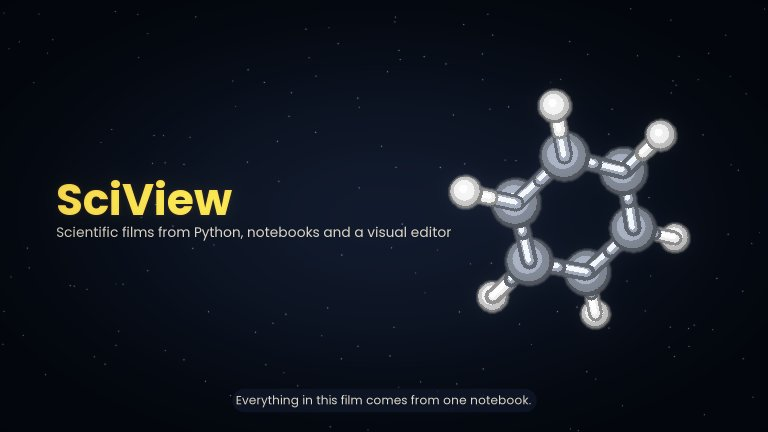

In [4]:
s = film.scenes[0]
s.name = "SciView"
s.camera.set("distance", 120).set("elevation", 25).set("azimuth", -90).set("offset", (480, 0))
film.add("title", text="SciView", subtitle="Scientific films from Python, notebooks and a visual editor",
         position=(140, 420), title_size=110, subtitle_size=34, start=0.3)
mol = film.add("molecule", model="assets/benzene.xyz", style="ball_and_stick", scale=7.0, start=0.2)
mol.key("rotation", 0, (75, 0, -25), "linear").key("rotation", 7, (75, 140, 25), "linear")
film.add("caption", text="Everything in this film comes from one notebook.", style="box", start=1.2, end=6.8)
show(s, 4.0)

### 2. 3D scenes: a beamline

Boxes, meshes (OBJ or STL), beams of particles that scatter in the sample, a detector screen whose image builds
up count by count, 3D labels, a scale bar and a camera that moves with keyframes.

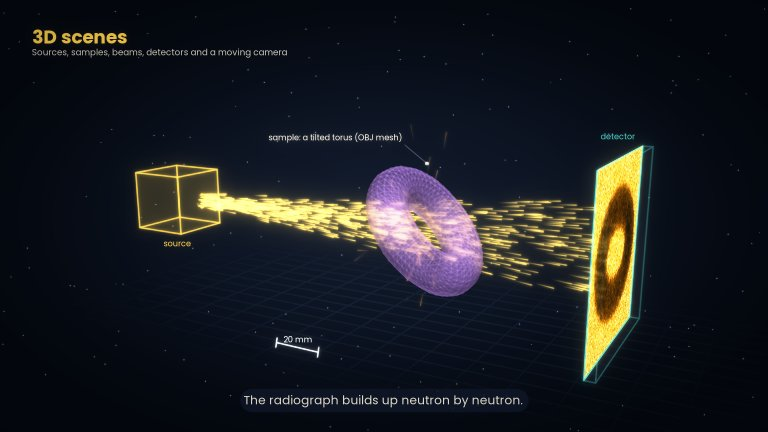

In [5]:
s = film.add_scene("3D scenes", 9.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="3D scenes", subtitle="Sources, samples, beams, detectors and a moving camera", start=0.2)
cam = s.camera
cam.set("target", (-10, 0, 0)).set("fov", 32).set("offset", (0, 20))
cam.key("azimuth", 0, -120).key("azimuth", 9, -55, "in_out")
cam.key("elevation", 0, 24).key("elevation", 9, 12, "in_out")
cam.key("distance", 0, 190).key("distance", 9, 160, "in_out")
film.add("grid3d", center=(-10, 0, -20), size=(150, 80), start=0.2)
film.add("box", center=(-70, 0, 0), size=(14, 14, 14), edge_color="gold", fill_color="gold", label="source",
         label_color="gold", label_position="below", start=0.4)
film.add("beam", source=(-62, 0, 0), target=(38, 0, 0), source_radius=2, target_radius=10, scatter_fraction=0.15,
         scatter_at=0.62, start=0.8)
film.add("mesh", model="assets/torus.obj", scale=11, style="solid+edges", color="violet", edge_color="violet",
         start=0.6)
det = film.add("screen", center=(40, 0, 0), size=(36, 36), thickness=2, image="assets/radiograph.png",
               colormap="gold", counts=60, flip=True, label="detector", label_color="teal", start=0.6)
det.key("buildup", 1.5, 0.0, "linear").key("buildup", 8.0, 1.0, "linear")
film.add("label3d", point=(0, 0, 14), text="sample: a tilted torus (OBJ mesh)", offset=(-60, -50), start=1.2)
film.add("scalebar3d", origin=(-20, -26, -20), length=10, unit="2 mm", start=1.5)   # unit: one scene unit
film.add("caption", text="The radiograph builds up neutron by neutron.", style="box", start=2.0, end=8.8)
show(s, 6.5)

### 3. Charts from data

Axes, measured points with error bars from a CSV file, a fit done by SciView (its formula in the label), an
uncertainty band from expressions, and a marker that follows the fitted curve.

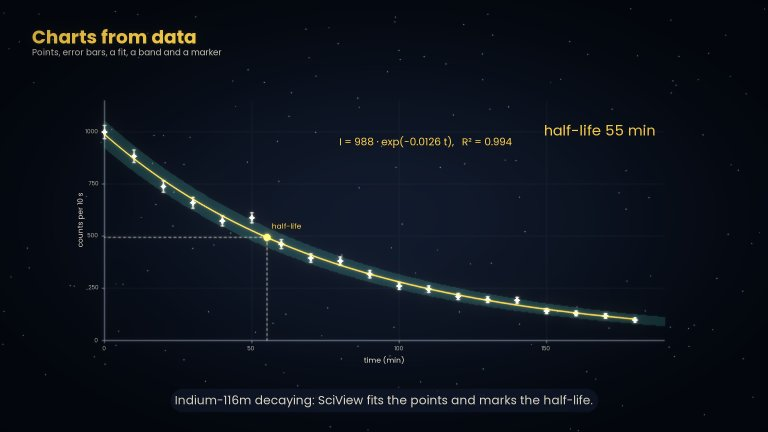

In [6]:
s = film.add_scene("Charts", 9.0, transition="push_left", transition_duration=0.8)
film.add("title", text="Charts from data", subtitle="Points, error bars, a fit, a band and a marker", start=0.2)
ax = film.add("axes", position=(260, 250), size=(1400, 600), x_range=(0, 190), y_range=(0, 1150),
              x_label="time (min)", y_label="counts per 10 s", x_ticks=5, y_ticks=5, start=0.3)
film.add("band", axes=ax, center=f"{A0:.2f}*exp(-x/{TAU:.3f})", spread=f"2*sqrt({A0:.2f}*exp(-x/{TAU:.3f}))",
         color="teal", fill_opacity=0.18, center_line=False, start=2.6)
film.add("errorbars", axes=ax, data="assets/decay.csv", x_column="t", y_column="counts", y_error="error",
         color="cream", start=0.9)
fit = film.add("fit", axes=ax, data="assets/decay.csv", x_column="t", y_column="counts", model="exponential",
               color="gold", style="solid", label="I = {a:.0f} · exp({b:.4f} t),   R² = {r2:.3f}",
               label_at=(0.42, 0.14), label_size=26, start=2.0)
fit.enter_duration = 1.5
mark = film.add("marker", axes=ax, x=0, follow=f"{A0:.2f}*exp(-x/{TAU:.3f})", color="gold", guides="both",
                label="half-life", start=4.5)
half = TAU * np.log(2)
mark.key("x", 4.6, 0.0).key("x", 6.6, half, "in_out")
film.add("text", text=f"half-life {half:.0f} min", position=(1640, 300), size=36, color="gold", align="right",
         start=6.8)
film.add("caption", text="Indium-116m decaying: SciView fits the points and marks the half-life.", style="box",
         start=1.0, end=8.8)
show(s, 7.5)

### 4. Spectra and maps

A spectrum from an expression with its peaks found and labelled automatically, and a heat map of a function of
x, y and time with its colour bar.

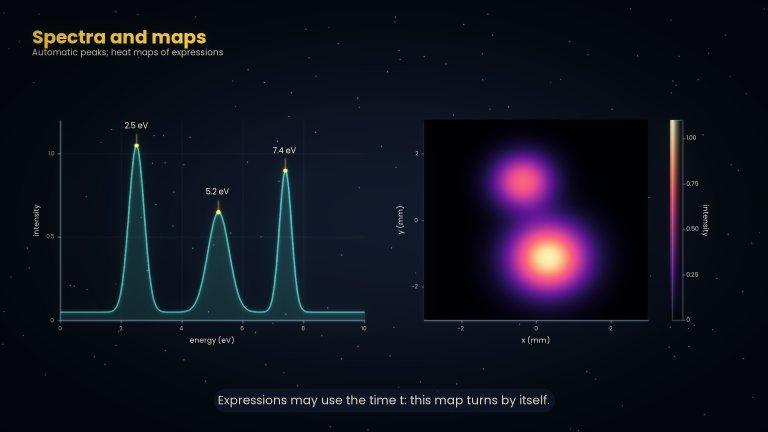

In [7]:
s = film.add_scene("Spectra and maps", 8.0, transition="wipe_left", transition_duration=0.8)
film.add("title", text="Spectra and maps", subtitle="Automatic peaks; heat maps of expressions", start=0.2)
ax1 = film.add("axes", position=(150, 300), size=(760, 500), x_range=(0, 10), y_range=(0, 1.2), x_label="energy (eV)",
               y_label="intensity", start=0.3)
film.add("spectrum", axes=ax1, source="expression",
         expression="gauss(x, 2.5, 0.25) + 0.6*gauss(x, 5.2, 0.35) + 0.85*gauss(x, 7.4, 0.2) + 0.05",
         label_format="{x:.1f} eV", label_size=20, start=0.8)
ax2 = film.add("axes", position=(1060, 300), size=(560, 500), x_range=(-3, 3), y_range=(-3, 3), x_label="x (mm)",
               y_label="y (mm)", grid=False, start=0.3)
film.add("heatmap", axes=ax2, expression="exp(-((x-1.2*cos(t))^2 + (y-1.2*sin(t))^2)) + "
                                         "0.7*exp(-((x+1.2*cos(t))^2 + (y+1.2*sin(t))^2)/0.6)",
         colormap="magma", vmin=0, vmax=1.1, start=0.8)
film.add("colorbar", colormap="magma", vmin=0, vmax=1.1, label="intensity", position=(1680, 300), size=(26, 500),
         start=1.0)
film.add("caption", text="Expressions may use the time t: this map turns by itself.", style="box", start=1.5,
         end=7.8)
show(s, 5.0)

### 5. Fields

A vector field and streamlines from expressions for u and v, with the dashes flowing along the field.

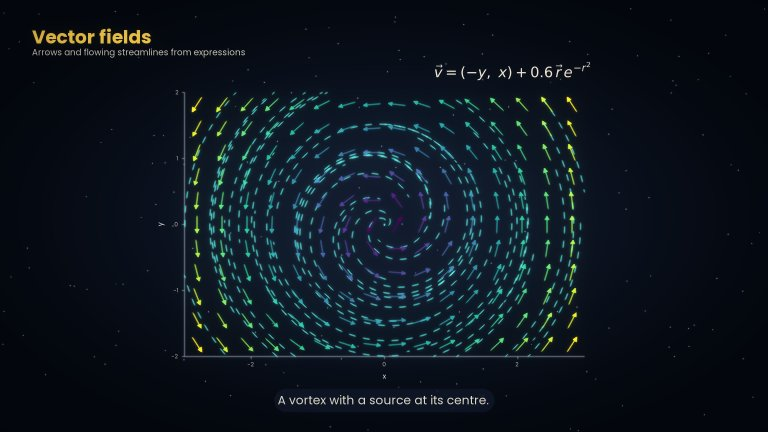

In [8]:
s = film.add_scene("Fields", 7.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="Vector fields", subtitle="Arrows and flowing streamlines from expressions", start=0.2)
ax = film.add("axes", position=(460, 230), size=(1000, 660), x_range=(-3, 3), y_range=(-2, 2), x_label="x",
              y_label="y", grid=False, start=0.3)
U, V = "-y + 0.6*x*exp(-(x^2+y^2))", "x + 0.6*y*exp(-(x^2+y^2))"
film.add("streamlines", axes=ax, u=U, v=V, seeds=36, color="teal", flow_speed=60, start=0.6)
film.add("vectorfield", axes=ax, u=U, v=V, grid=(16, 11), normalize=True, length=0.7, colormap="viridis",
         start=1.6)
film.add("equation", tex=r"\vec{v} = (-y,\ x) + 0.6\,\vec{r}\,e^{-r^2}", position=(1480, 180), size=36,
         align="right", start=2.0)
film.add("caption", text="A vortex with a source at its centre.", style="box", start=1.2, end=6.8)
show(s, 4.0)

### 6. Images

An image with a scale bar from its pixel size; then its pixels leave the image and fall into a histogram of
their grey values (`morph`).

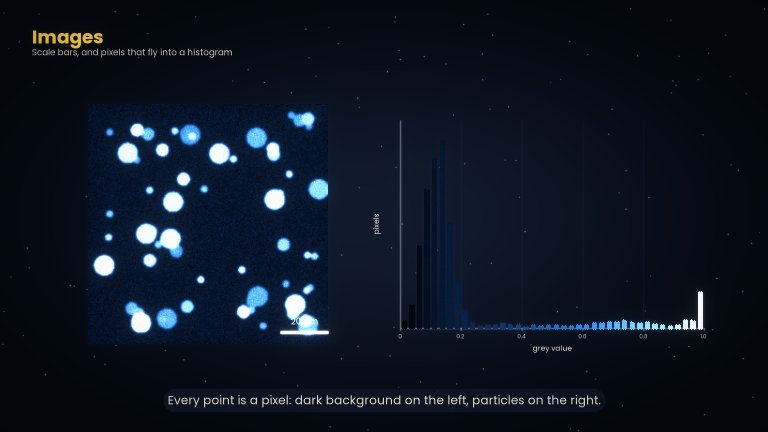

In [9]:
s = film.add_scene("Images", 9.0, transition="push_up", transition_duration=0.8)
film.add("title", text="Images", subtitle="Scale bars, and pixels that fly into a histogram", start=0.2)
img = film.add("image", image="assets/particles.png", position=(520, 560), width=600, colormap="ice", start=0.3)
film.add("scalebar", reference=img.id, pixel_size="0.4 µm", length="20 µm", position=(760, 830), start=0.8)
ax = film.add("axes", position=(1000, 300), size=(760, 520), x_range=(0, 1), y_range=(0, 1), x_label="grey value",
              y_label="pixels", y_ticks=0, start=2.0)
m = film.add("morph", source=img.id, axes=ax, target="histogram", bins=40, max_points=4000, colormap="ice",
             color_mode="value", start=2.2)
m.key("progress", 2.6, 0.0).key("progress", 6.5, 1.0, "in_out")
film.add("caption", text="Every point is a pixel: dark background on the left, particles on the right.",
         style="box", start=2.5, end=8.8)
show(s, 7.5)

### 7. Tomography

The sinogram of a phantom is recorded angle by angle, and the filtered back-projection follows it. Notebook 1
shows a whole tomography experiment.

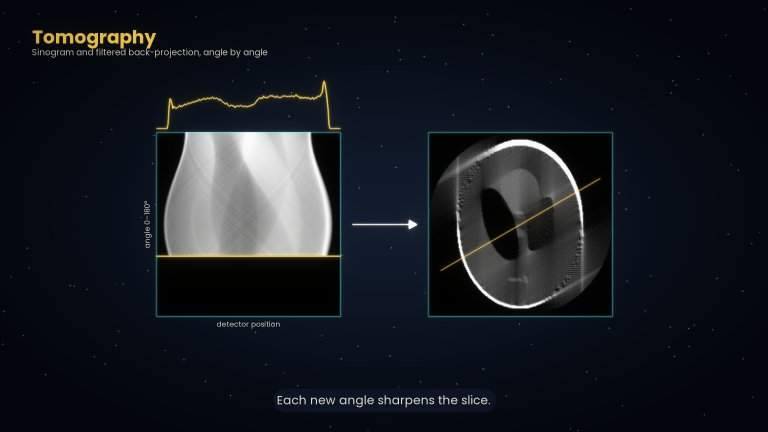

In [10]:
s = film.add_scene("Tomography", 8.0, transition="zoom", transition_duration=0.8)
film.add("title", text="Tomography", subtitle="Sinogram and filtered back-projection, angle by angle", start=0.2)
sino = film.add("sinogram", source="phantom", angles=180, position=(620, 560), size=(460, 460), profile=True,
                start=0.3)
sino.key("progress", 0.8, 0.0, "linear").key("progress", 7.0, 1.0, "linear")
film.add("backprojection", sinogram=sino.id, position=(1300, 560), size=(460, 460), start=0.3)
film.add("arrow", tail=(880, 560), tip=(1040, 560), start=0.6)
film.add("caption", text="Each new angle sharpens the slice.", style="box", start=1.0, end=7.8)
show(s, 5.0)

### 8. Optics

Lenses and mirrors in a ray tracer (thin-lens approximation), light travelling along the rays, and wavefronts.

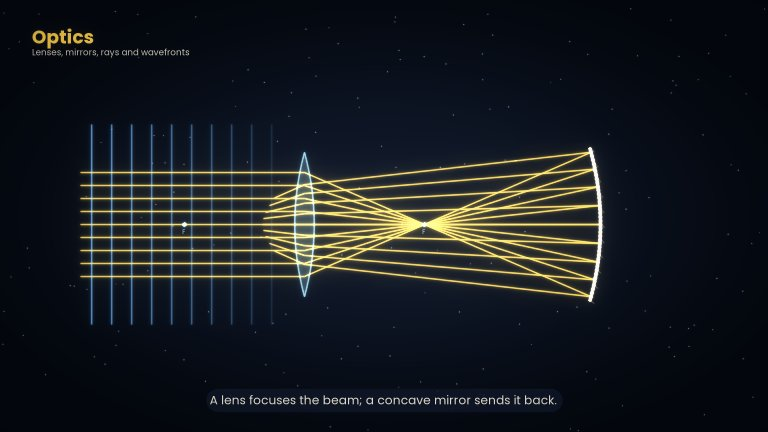

In [11]:
s = film.add_scene("Optics", 8.0, transition="dip", transition_duration=0.8)
film.add("title", text="Optics", subtitle="Lenses, mirrors, rays and wavefronts", start=0.2)
film.add("lens", position=(760, 560), focal=300, height=360, start=0.3)
film.add("mirror", position=(1500, 560), angle=180, radius=700, height=380, start=0.3)
rays = film.add("rays", source=(200, 560), kind="parallel", spread=260, count=9, bounces=3, start=0.6)
rays.key("travel", 0.8, 0.0, "linear").key("travel", 5.5, 1.0, "linear")
film.add("wavefront", source=(200, 560), kind="plane", wavelength=50, extent=500, range=520, color="blue",
         start=0.6)
film.add("caption", text="A lens focuses the beam; a concave mirror sends it back.", style="box", start=1.0,
         end=7.8)
show(s, 5.0)

### 9. Text, equations and counters

LaTeX equations, text that types itself, numbers that count with SI prefixes, and the caption styles.

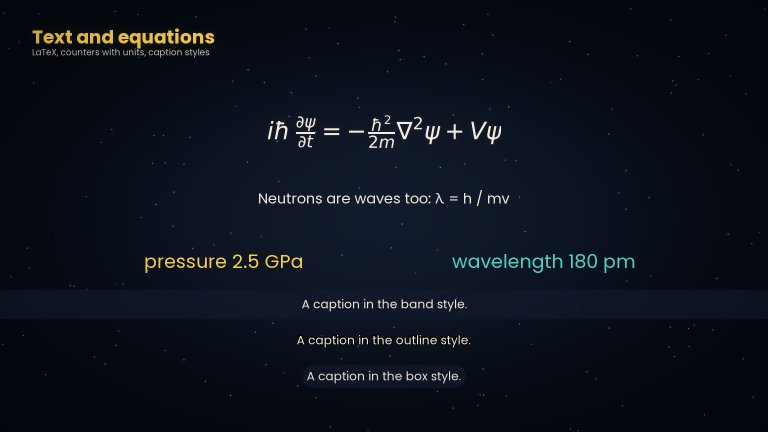

In [12]:
s = film.add_scene("Text", 8.0, transition="wipe_up", transition_duration=0.8)
film.add("title", text="Text and equations", subtitle="LaTeX, counters with units, caption styles", start=0.2)
film.add("equation", tex=r"i\hbar\,\frac{\partial \psi}{\partial t} = -\frac{\hbar^2}{2m}\nabla^2\psi + V\psi",
         position=(960, 330), size=60, start=0.4)
film.add("text", text="Neutrons are waves too: λ = h / mv", position=(960, 470), size=36, align="center",
         start=1.2, enter="typewriter")
pressure = film.add("text", text="pressure {value:si:Pa}", position=(560, 620), size=48, color="gold",
                    align="center", start=2.0)
pressure.key("value", 2.0, 1e3, "in").key("value", 6.0, 2.5e9, "in")
length = film.add("text", text="wavelength {value:.2si:m}", position=(1360, 620), size=48, color="teal",
                  align="center", start=2.0)
length.key("value", 2.0, 5e-9).key("value", 6.0, 1.8e-10)
for k, style in enumerate(("band", "outline", "box")):
    film.add("caption", text=f"A caption in the {style} style.", style=style, position=(960, 760 + 90 * k),
             start=3.0 + 0.5 * k, end=7.8)
show(s, 6.5)

### 10. Your own matplotlib figures

When a plot needs something SciView does not draw, a matplotlib function draws it, at every frame, with the time
`t`. The project file keeps only the function's name and a snapshot, so the animation is redrawn when this
notebook (or your script) renders the film. Films with script figures render in one process.

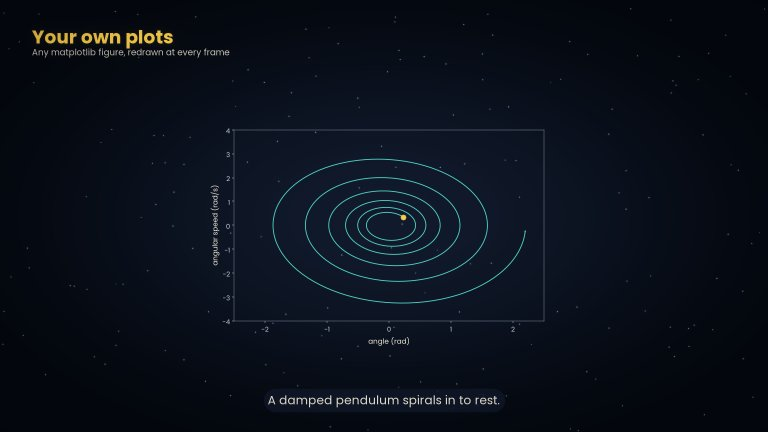

In [13]:
s = film.add_scene("Matplotlib", 8.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="Your own plots", subtitle="Any matplotlib figure, redrawn at every frame", start=0.2)


def phase_portrait(fig, t):
    """A damped pendulum's trajectory in phase space, drawn up to the time t."""
    ax = fig.subplots()
    time = np.linspace(0, 30, 1500)
    angle = 2.2 * np.exp(-time / 12) * np.cos(1.6 * time)
    speed = np.gradient(angle, time)
    n = max(2, int(len(time) * min(t / 6.5, 1)))
    ax.plot(angle[:n], speed[:n], color="#4fd1c5", lw=1.6)
    ax.plot(angle[n - 1], speed[n - 1], "o", color="#ffcf4a", ms=9)
    ax.set_xlim(-2.5, 2.5)
    ax.set_ylim(-4, 4)
    ax.set_xlabel("angle (rad)")
    ax.set_ylabel("angular speed (rad/s)")


film.add_figure(phase_portrait, name="Phase portrait", position=(960, 560), size=(1000, 620), start=0.4)
film.add("caption", text="A damped pendulum spirals in to rest.", style="box", start=1.0, end=7.8)
show(s, 5.0)

### 11. Groups, keyframes and easing

Any property can be keyframed, with an easing per keyframe. A group moves, scales and fades its members
together.

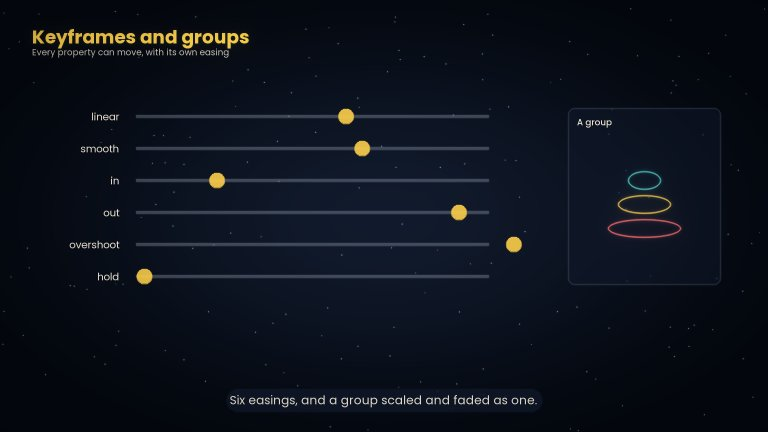

In [14]:
s = film.add_scene("Keyframes", 8.0, transition="push_left", transition_duration=0.8)
film.add("title", text="Keyframes and groups", subtitle="Every property can move, with its own easing", start=0.2)
for k, ease in enumerate(("linear", "smooth", "in", "out", "overshoot", "hold")):
    y = 290 + 80 * k
    film.add("text", text=ease, position=(300, y - 18), size=26, align="right", start=0.4)
    film.add("rect", position=(340, y - 2), size=(880, 4), fill_color="gray", fill_opacity=0.4, stroke_width=0,
             start=0.4)
    dot = film.add("ellipse", center=(360, y), radii=(18, 18), fill_color="gold", fill_opacity=0.9, stroke_width=0,
                   start=0.4)
    dot.key("center", 1.2, (360, y)).key("center", 4.2, (1200, y), ease)     # the easing of the move into this key
panel = film.add("panel", title="A group", position=(1420, 270), size=(380, 440), start=0.4)
inside = [film.add("ellipse", center=(1610, 450 + 60 * k), radii=(40 + 25 * k, 22), stroke_color=c, start=0.4)
          for k, c in enumerate(("teal", "gold", "pore"))]
grp = film.group([panel, *inside], name="Group", pivot=(1610, 490))
grp.key("scale", 4.5, 1.0).key("scale", 5.5, 0.7, "out").key("scale", 6.5, 1.0, "overshoot")
grp.key("opacity", 4.5, 1.0).key("opacity", 5.5, 0.4).key("opacity", 6.5, 1.0)
film.add("caption", text="Six easings, and a group scaled and faded as one.", style="box", start=1.0, end=7.8)
show(s, 3.0)

### 12. The end card

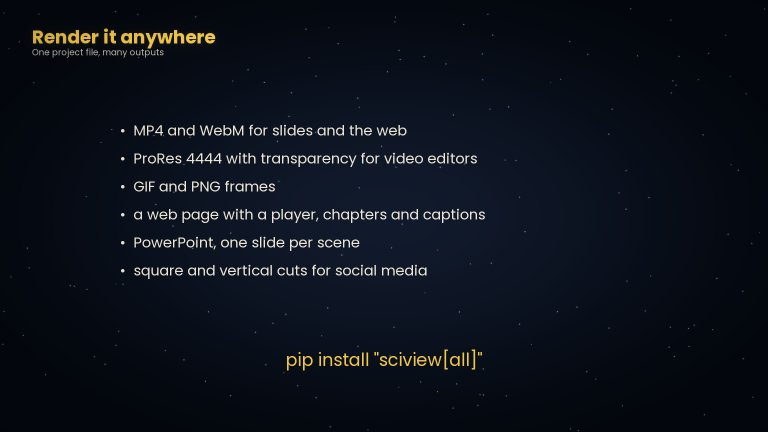

In [15]:
s = film.add_scene("Export", 7.0, transition="crossfade", transition_duration=0.8)
film.add("title", text="Render it anywhere", subtitle="One project file, many outputs", start=0.2)
formats = ["MP4 and WebM for slides and the web", "ProRes 4444 with transparency for video editors",
           "GIF and PNG frames", "a web page with a player, chapters and captions",
           "PowerPoint, one slide per scene", "square and vertical cuts for social media"]
for k, line in enumerate(formats):
    film.add("text", text=f"•  {line}", position=(300, 300 + 70 * k), size=36, start=0.6 + 0.4 * k)
film.add("text", text='pip install "sciview[all]"', position=(960, 870), size=44, color="gold", align="center",
         start=3.4)
show(s, 5.5)

## Check the film

`validate` finds missing files and broken references; `sciview.checks` looks at rendered frames for text with
poor contrast and text that overlaps; `sciview.schema` checks the project file against the published JSON
Schema (with `jsonschema` installed).

In [16]:
print(film.validate() or "no problems")
issues = checks.frame_issues(film)
print(f"{len(issues)} layout or contrast notes")
for issue in issues[:5]:
    print("  ", issue["message"])
film.save()
print("schema:", schema.validate(film.to_json()) or "valid")
print(f"{len(film.scenes)} scenes, {film.duration:.1f} s")
for start, _end, title in film.chapters():
    print(f"  {start:5.1f} s  {title}")

no problems
0 layout or contrast notes
schema: valid
12 scenes, 87.2 s
    0.0 s  SciView
    6.6 s  3D scenes
   14.8 s  Charts
   23.0 s  Spectra and maps
   30.2 s  Fields
   36.4 s  Images
   44.6 s  Tomography
   51.8 s  Optics
   59.0 s  Text
   66.2 s  Matplotlib
   73.4 s  Keyframes
   80.6 s  Export



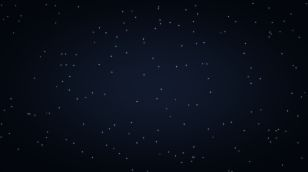

In [17]:
film.preview(fps=2, scale=0.16)

## Themes

A theme changes the palette, background, fonts and the look of titles and captions in one call. Here, a copy
of the film in the light theme, for printed handouts:

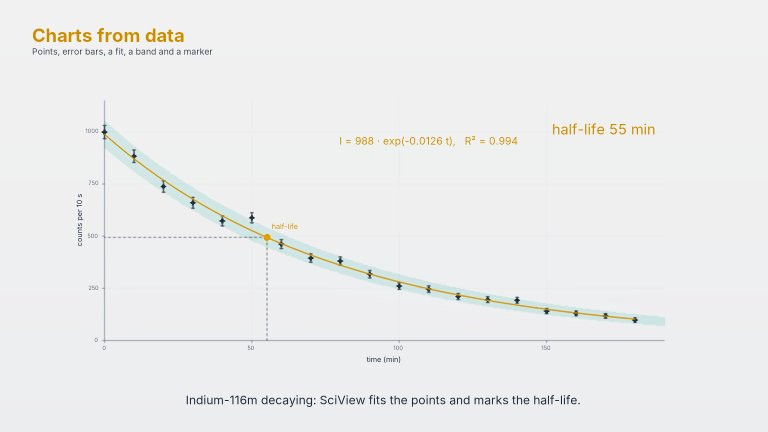

In [18]:
light = film.copy()
light.apply_theme("light")
still(light, film.scene_start("Charts") + 7.5, 0.4)

## Export

`render` picks the format from the file name; `target` chooses a preset (`slides`, `conference`, `poster`,
`square`, `vertical`, `overlay`, `web`, `preview`). The full film goes to MP4 at half size; to keep the notebook
quick, the other formats use a short excerpt (the first two scenes) at a quarter of the size.

In [19]:
video = film.render(FILM / "tour.mp4", scale=0.5)
print(f"{video.name}: {video.stat().st_size / 1e6:.1f} MB")

poster = film.render(FILM / "poster.png", target="poster", time=film.scene_start("Charts") + 7.5, scale=0.5)
(FILM / "tour.srt").write_text(film.captions_srt(), encoding="utf-8")

excerpt = film.copy()
for scene in list(excerpt.scenes)[2:]:
    excerpt.remove_scene(scene)
outputs = [
    excerpt.render(FILM / "excerpt.gif", scale=0.25, fps=10),
    excerpt.render(FILM / "excerpt_vertical.mp4", target="vertical", scale=0.25),
    excerpt.render(FILM / "excerpt.html", scale=0.25),
    excerpt.render(FILM / "excerpt.pptx", scale=0.25),
]
for path in [poster, FILM / "tour.srt", *outputs]:
    print(f"{path.name:24s} {path.stat().st_size / 1e3:8.0f} kB")

tour.mp4: 8.6 MB
poster.png                    383 kB
tour.srt                        1 kB
excerpt.gif                  2688 kB
excerpt_vertical.mp4          833 kB
excerpt.html                 1534 kB
excerpt.pptx                 1321 kB
